# 01 测井数据探索与窗口化

配套《油气藏多源数据智能表征方法与系统研究》。

**用途**：拿到一口新井的 LAS 后，先在这里看清它长什么样、缺什么、能切多少窗口，再进模型。

**内核**：选 `Python (reservoir-repr)`。

In [1]:
import sys, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, lasio

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

print('python      ', sys.version.split()[0])
print('numpy       ', np.__version__)
print('pandas      ', pd.__version__)
print('torch       ', torch.__version__)
print('cuda 可用   ', torch.cuda.is_available())
if torch.cuda.is_available():
    print('显卡        ', torch.cuda.get_device_name(0))

python       3.12.3
numpy        2.5.4
pandas       3.1.1
torch        2.6.0+cu124
cuda 可用    True
显卡         NVIDIA GeForce RTX 4060 Laptop GPU


## 1  读取 LAS

先自动定位到工程根目录（notebook 默认在 `notebooks/` 下运行）。

没有真实数据时先用合成井：`make_demo_las.py` 会生成 `data/raw/DEMO-01.las`。

In [2]:
import os
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'data').is_dir():
    ROOT = ROOT.parent
os.chdir(ROOT)
print('工程根目录:', ROOT)

工程根目录: C:\油气藏多源数据表征\reservoir-repr


In [3]:
from pathlib import Path

LAS_PATH = Path('data/raw/DEMO-01.las')
assert LAS_PATH.exists(), '先运行 python make_demo_las.py 生成合成井'

las = lasio.read(LAS_PATH)
well = str(las.well.WELL.value)
depth = np.asarray(las.index, dtype=float)
step = float(np.median(np.diff(depth)))

print(f'井名   : {well}')
print(f'深度   : {depth[0]:.2f} – {depth[-1]:.2f} m，{depth.size} 点')
print(f'采样   : {step:.3f} m')
print(f'曲线   : {", ".join(c.mnemonic for c in las.curves)}')

井名   : DEMO-01
深度   : 2100.00 – 2159.88 m，480 点
采样   : 0.125 m
曲线   : DEPT, GR, SP, CAL, RT, DEN, CNU, AC, CPOR


## 2  质量概览

缺失率、值域、尖峰数量。

In [4]:
curves = {}
for c in las.curves:
    arr = np.asarray(c.data, dtype=float)
    arr = np.where(arr <= -900, np.nan, arr)
    curves[c.mnemonic] = arr

rows = []
for k, a in curves.items():
    if k == 'DEPT':
        continue
    v = a[np.isfinite(a)]
    rows.append({
        '通道': k,
        '缺失率': f'{np.isnan(a).mean():.1%}',
        '最小': round(float(v.min()), 3) if v.size else None,
        '最大': round(float(v.max()), 3) if v.size else None,
        '点数': int(np.isfinite(a).sum()),
    })
pd.DataFrame(rows)

,通道,缺失率,最小,最大,点数
0,GR,2.3%,24.431,99.835,469
1,SP,0.0%,-31.624,-2.811,480
2,CAL,0.0%,8.233,12.024,480
3,RT,0.0%,4.845,687.274,480
4,DEN,2.3%,2.233,2.576,469
5,CNU,0.0%,0.066,0.235,480
6,AC,2.3%,66.032,93.652,469
7,CPOR,97.5%,0.120,0.223,12


## 3  四道曲线图

缺失段会自动涂灰。

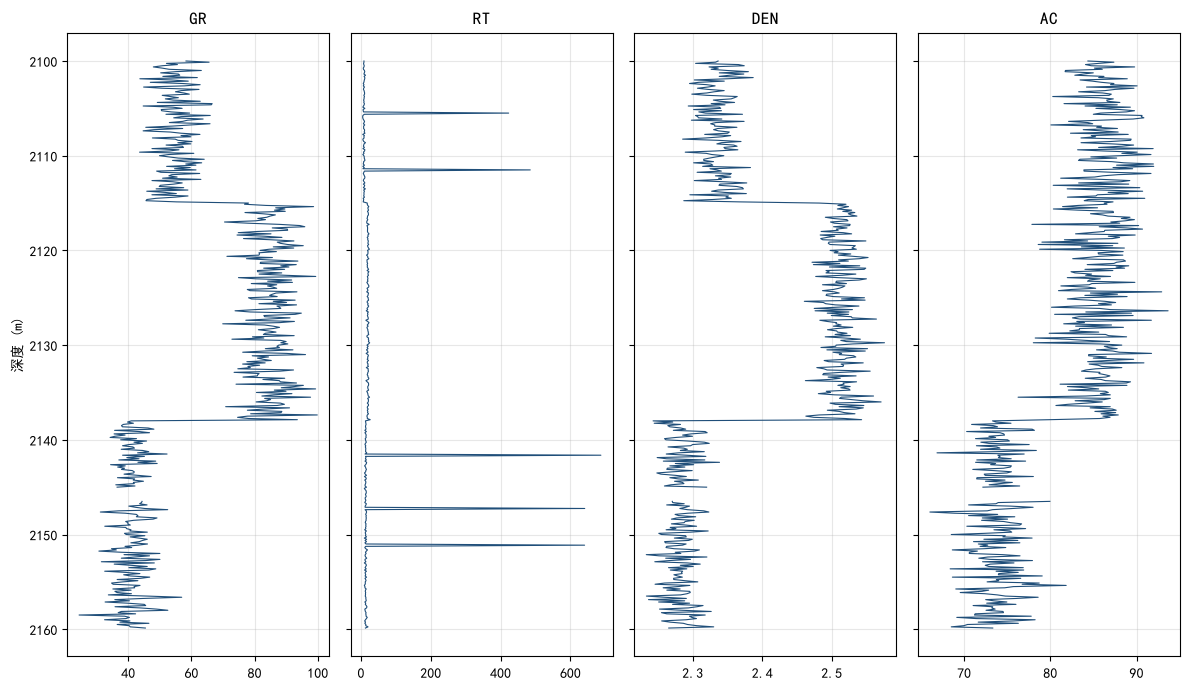

In [5]:
show = [k for k in ('GR', 'RT', 'DEN', 'AC') if k in curves]
fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 7), sharey=True)
for ax, k in zip(axes, show):
    ax.plot(curves[k], depth, lw=0.8, color='#1f4e79')
    ax.set_title(k)
    ax.grid(alpha=0.3)
axes[0].invert_yaxis()
axes[0].set_ylabel('深度 (m)')
plt.tight_layout()
plt.show()

## 4  窗口化

按 2 m / 50% 重叠切窗。留意每窗的深度点数 —— 2 m ÷ 0.125 m = **16 点**，
这正是 Transformer 在这套参数下发挥不出长程建模能力的原因，正式模型要用更长的上下文窗口。

In [6]:
WINDOW_M, OVERLAP = 2.0, 0.5
names = [k for k in curves if k not in ('DEPT', 'CPOR')]
L = int(round(WINDOW_M / step))
stride = max(1, int(round(L * (1 - OVERLAP))))
arr = np.stack([curves[k] for k in names])
n_win = max(0, (depth.size - L) // stride + 1)

win = np.empty((n_win, len(names), L), dtype=np.float32)
presence = np.ones((n_win, len(names)), dtype=np.int8)
for i in range(n_win):
    s = i * stride
    block = arr[:, s:s + L]
    win[i] = block
    presence[i] = (np.isfinite(block).sum(axis=1) > 0).astype(np.int8)

print(f'窗口数 {n_win}，形状 {win.shape}（窗口 × 通道 × 深度点）')
print(f'每窗深度点数 {L}，步长 {stride}')
print(f'窗口内缺失采样占比 {np.isnan(win).mean():.1%}')

窗口数 59，形状 (59, 7, 16)（窗口 × 通道 × 深度点）
每窗深度点数 16，步长 8
窗口内缺失采样占比 1.0%


## 5  存盘

产出可直接被训练脚本读取。

In [7]:
out = Path('data/processed') / f'{well}_win.npz'
out.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(out, win=win, presence=presence, channels=np.array(names))
print('saved ->', out)

chk = np.load(out)
print('读取校验:', chk['win'].shape, chk['channels'].tolist())

saved -> data\processed\DEMO-01_win.npz
读取校验: (59, 7, 16) ['GR', 'SP', 'CAL', 'RT', 'DEN', 'CNU', 'AC']


---

### 换成真实井

把 `LAS_PATH` 改成 `data/raw/W-01.las` 之类的真实文件重跑即可；
若曲线命名与默认不一致（如 `RHOB` 而非 `DEN`），通道匹配逻辑见 `smoke_las.py` 的 `match_channels`。